# 4. Join your data by edge_id

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/04_join_by_edge_id.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/04_join_by_edge_id.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-4.svg" alt="duckOSM notebook manual, chapter 4: Join your data by edge_id" width="100%">

| **You learn** | why `edge_id` is the key of your data; the type of `edge_id`; a join in pandas and in SQL; the same data in more modes; a map and a dashboard of your data; a file of your data; the ids after a rebuild |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[viz]` (the install cell installs them) |
| **Next** | [5. Fix the OSM data once](05_osm_fixes.md): a fixes file that every build and every output takes |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## The goal of this chapter

You have data about roads from another source, for example a file of traffic counts from the city: one number for
each road and each direction. You want this data on the duckOSM network, so that you can sort the roads by it, query
it with SQL and color the map by it. At the end of the chapter you can:

1. give each row of your data its `edge_id`, the key of a duckOSM edge;
2. join your data to the edges in pandas or in SQL;
3. color the map and the dashboard by your data;
4. build the network again and find your data on the same roads.

## Your data and the edges

Much data about roads has one value for each road and each direction: traffic counts, measured speeds, noise, the
results of a model. To use it with a duckOSM network, each value needs the edge that it belongs to. The key of an
edge is `edge_id` (chapter 2, "What edge_id is").

| Key | Stable after a new build? | Same in each mode? | Use it to join? |
|---|---|---|---|
| `edge_id` | yes: it comes from `osm_id`, `source` and `target` | yes | **yes** |
| `edge_ref` (`4230114#3f`) | no: the part number changes when the way gets more nodes | yes | no, only to read |
| the row number | no: another build or another filter gives another order | no | no |
| `osm_id` | yes | yes | no: one way has many edges, in two directions |
| the geometry | almost: a small change of a node moves it | yes | no: use map matching (chapter 11) |

The flow of this chapter: you make the data once with `edge_id` in it, keep it in a file, and join it to the network
each time that you need it. The join is the same in pandas, in SQL and on the map.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> Keep `edge_id` in your data, and join on it. The same `edge_id` is in each new build of the same OSM data and in each mode, so your data stays on the correct roads.

The counts in this chapter are made up. Real counts come from sensors: chapter 11 shows how to put GPS points and
sensor data onto the edges.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The counts are on the driving network.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                                   # the card

Network('monaco.duckdb', 52.7 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

## Make the counts

In real work, a file from the city gives one count for each direction of the main roads. Here you make the counts
yourself, in three steps:

1. Get the main roads: the primary, secondary and tertiary edges of the driving network.
2. Give each edge a base count by its road class: 900 vehicles per hour for a primary road, 500 for a secondary road
   and 250 for a tertiary road.
3. Multiply each base count by a random number from 0.5 to 1.5. The seed `1` gives the same numbers in each run.

The result is a table with two columns: `edge_id` and the count.

In [3]:
import numpy as np
import pandas as pd

main = net.driving.edges(where="highway IN ('primary', 'secondary', 'tertiary')")    # step 1: the main roads
base = main.highway.map({"primary": 900, "secondary": 500, "tertiary": 250})       # step 2: the base count of each edge

In [4]:
rng = np.random.default_rng(1)                                   # step 3: random numbers, the same in each run
vph = (base * rng.uniform(0.5, 1.5, len(main))).round().astype(int)
counts = pd.DataFrame({"edge_id": main.edge_id, "vehicles_per_hour": vph})    # your data: edge_id and the count
print(len(counts), "rows")
counts.head()

1013 rows


,edge_id,vehicles_per_hour
0,24138324208710596,506
1,25722618171067748,1305
2,27407470953641313,322
3,30114210838040685,724
4,54233354089271892,406


Each row is one edge: one direction of one part of a road. The table has 1013 rows,
one for each primary, secondary and tertiary edge.

### The type of `edge_id`

`edge_id` is a 64-bit integer, with up to 19 digits. A `float64` keeps only approximately 16 digits, so a float
changes most ids. The cell turns the ids into floats and back, and counts the ids that changed.

In [5]:
print(counts.dtypes)                                            # edge_id is int64
broken = counts.edge_id.astype("float64").astype("int64")       # through a float, and back
print((broken != counts.edge_id).sum(), "of", len(counts), "ids changed")

edge_id              int64
vehicles_per_hour    int64
dtype: object
1007 of 1013 ids changed


1007 of the 1013 ids changed: a join on them finds almost no edges. Only the 6
small ids stay the same.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Keep `edge_id` as `int64` (`BIGINT` in SQL). A float column, a spreadsheet program or a JSON reader that reads each number as a float changes the ids. pandas reads a CSV file of integers as `int64`, and Parquet keeps the type. In a spreadsheet, keep the column as text.

## Join on `edge_id`

`pandas.merge` joins the counts to the edges. `how="left"` keeps all edges: an edge without a count gets `NaN`. Then
you have all columns of the edge next to its count.

In [6]:
gdf = net.driving.edges().merge(counts, on="edge_id", how="left")                    # the edges with their counts
gdf.nlargest(5, "vehicles_per_hour")[["edge_id", "name", "highway", "vehicles_per_hour"]]    # the five largest counts

,edge_id,name,highway,vehicles_per_hour
2246,7273866584570309072,None,primary,1324.0
650,2112309560693974313,Boulevard du Larvotto,primary,1312.0
652,2113142360788194299,None,primary,1309.0
2610,8528436742631886103,Tunnel Pasteur,primary,1308.0
607,1943370964926618174,Tunnel Albert II,primary,1307.0


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The five largest counts (1307 to 1324) are on primary roads, near the top of their range (900 × 1.5 = 1350): the Boulevard du Larvotto, the tunnels Pasteur and Albert II, and two edges without a name. `gdf` is still a GeoDataFrame: it has the geometry of each edge.

In [7]:
print(gdf.vehicles_per_hour.notna().sum(), "of", len(gdf), "edges have a count")
gdf.groupby("highway").vehicles_per_hour.mean().dropna().round()       # the mean count of each road class

1013 of 2840 edges have a count


highway
primary      872.0
secondary    507.0
tertiary     253.0
Name: vehicles_per_hour, dtype: float64

1013 of the 2840 driving edges have a count. The mean count of each class is near
its base: approximately 900, 500 and 250.

### Join in SQL

The same join works in DuckDB. `con.register` gives your DataFrame a table name on the connection, so a query can join
it to the tables of the file. DuckDB computes the join, and only the result comes to Python.

The query in the cell below:

1. joins the driving edges (`driving.edges`, the name `e`) to your counts (`counts`, the name `c`) on `edge_id`
   (`USING (edge_id)`);
2. puts the rows in groups by road class (`GROUP BY e.highway`);
3. gives for each class the number of edges, the mean count, and the sum of count × length in km.

In [8]:
with net.connect() as con:                                      # a read-only connection to the file
    con.register("counts", counts)                              # your DataFrame as the table "counts"
    by_class = con.sql("""
        SELECT e.highway, count(*) AS edges, round(avg(c.vehicles_per_hour)) AS mean_vph,
               round(sum(c.vehicles_per_hour * e.length_m) / 1000) AS vehicle_km_per_hour
        FROM driving.edges e JOIN counts c USING (edge_id)
        GROUP BY e.highway ORDER BY mean_vph DESC
    """).df()
by_class

,highway,edges,mean_vph,vehicle_km_per_hour
0,primary,197,872.0,9886.0
1,secondary,429,507.0,7658.0
2,tertiary,387,253.0,3230.0


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> 197 primary, 429 secondary and 387 tertiary edges, with mean counts of 872, 507 and 253 vehicles per hour. `vehicle_km_per_hour` is the distance that all vehicles drive on the class in one hour: 9886 km on the primary roads.

### Your data in a file

Keep your data in a Parquet file: it keeps `edge_id` as `int64`. `net.sql` can read a Parquet file in the query, so
you do not need to read it into pandas first.

In [9]:
import os
os.makedirs("out", exist_ok=True)
counts.to_parquet("out/counts.parquet")                                     # your data, with its types
net.sql("""
    SELECT e.name, e.highway, c.vehicles_per_hour
    FROM driving.edges e JOIN 'out/counts.parquet' c USING (edge_id)
    WHERE e.name IS NOT NULL
    ORDER BY c.vehicles_per_hour DESC LIMIT 5
""")                                                                         # the file, joined in SQL

,name,highway,vehicles_per_hour
0,Boulevard du Larvotto,primary,1312
1,Tunnel Pasteur,primary,1308
2,Tunnel Albert II,primary,1307
3,Boulevard du Larvotto,primary,1290
4,Tunnel Rainier III,primary,1287


The five largest counts on named roads, from 1287 to 1312 vehicles per hour. DuckDB reads the Parquet file with the
path in the query. The path is from the folder of the notebook.

## Color the map by the counts

`color_by` takes your own data keyed by `edge_id` (chapter 3, "Color the roads by a column"). A Series with `edge_id`
as its index is the short form. The edges without a count are gray. Run the cell to see the live map: you can zoom,
and click a road to see its columns. This page shows the static picture of the map.

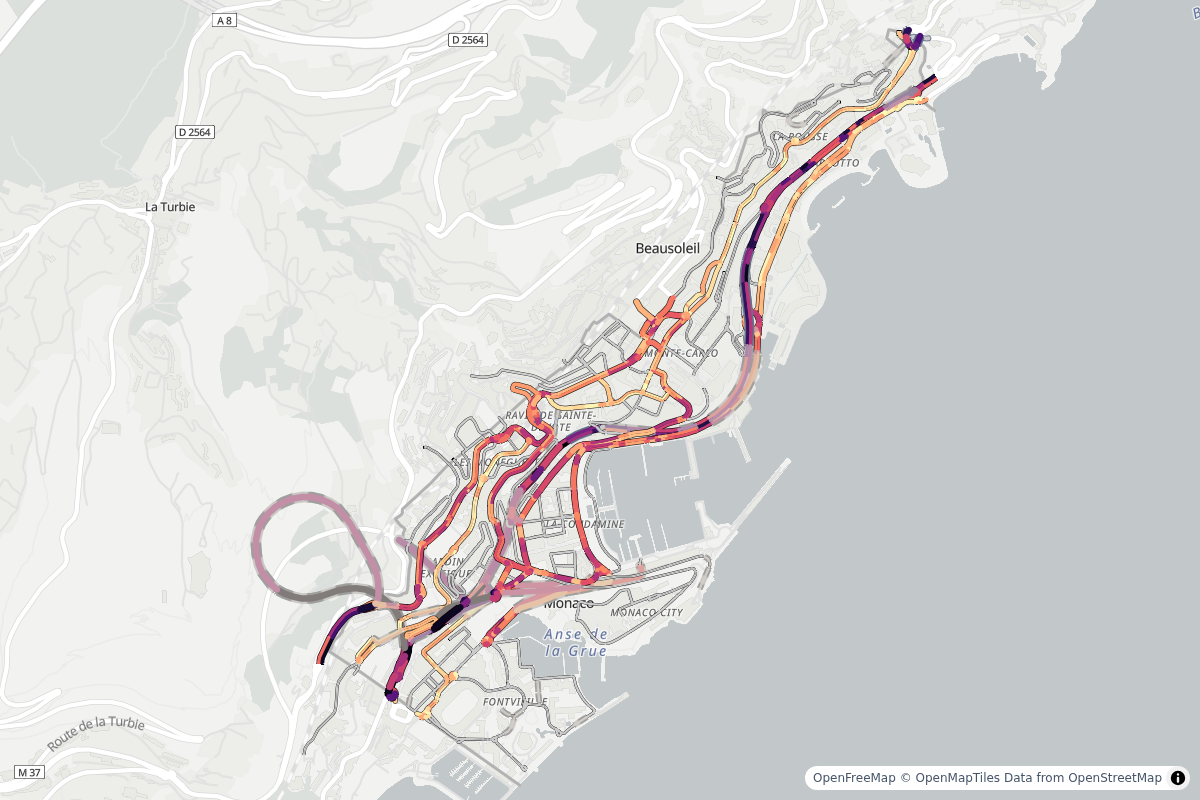

In [10]:
by_edge = counts.set_index("edge_id").vehicles_per_hour    # the counts as a Series keyed by edge_id
net.driving.map(color_by=by_edge, cmap="magma_r")                  # a map, colored by the count

The color bar is the count in vehicles per hour. The dark lines are the primary
roads with the largest counts. The thin gray lines are the edges without a count: the residential streets and the
service roads.

### Show only some edges: `highlight`

`color_by` also takes a DataFrame with `edge_id` and one value column (`color_by=counts` gives the same map), or the
name of a column of the edges. To show only some edges, give their ids to `highlight`. The cell shows the edges with
more than 1000 vehicles per hour.

65 busy edges


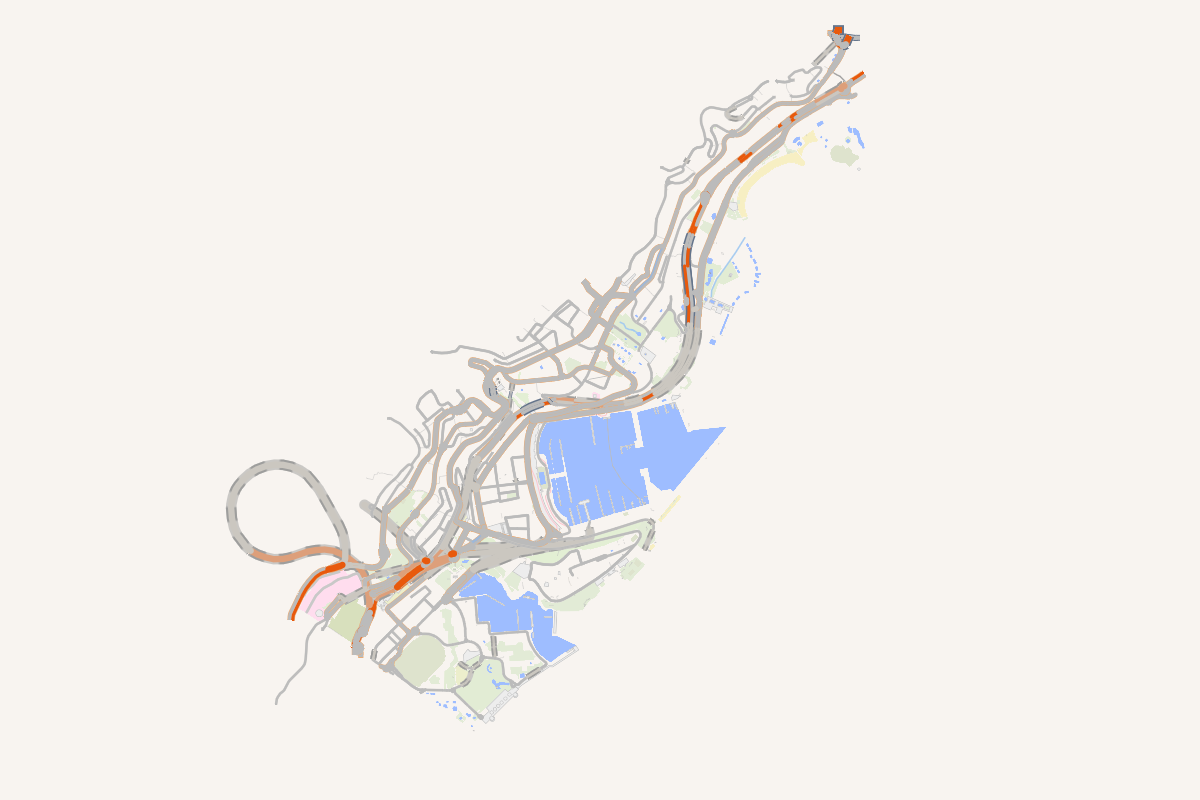

In [11]:
busy = counts[counts.vehicles_per_hour > 1000].edge_id      # the edges with more than 1000 vehicles per hour
print(len(busy), "busy edges")                              # the number of busy edges
net.driving.map(highlight=busy)                                     # in orange, the rest gray

65 edges are busy, all on primary roads, because only a primary road can have more than 1000 vehicles per hour
here (500 × 1.5 = 750 is the maximum of a secondary road).

### Save the map

`save_map` writes the same map as one HTML file, with the same options (chapter 3, "Save a map as a file"). Send
the file to a person who has no Python.

In [12]:
net.driving.save_map("out/counts.html", color_by=by_edge, cmap="magma_r")    # the same map as one HTML file

PosixPath('out/counts.html')

## A dashboard of your data

A map shows the pattern of your data: where the counts are high and where they are low. A **dashboard** also lets you
look at one road. It is the same colored map, with a panel at its left. When you click a road, the panel shows the
**card** of the road: its OSM data and the value of your data for it.

`net.dashboard()` takes the same `color_by` and `cmap` as `net.map()`. The cell below gives the dashboard of the
counts.

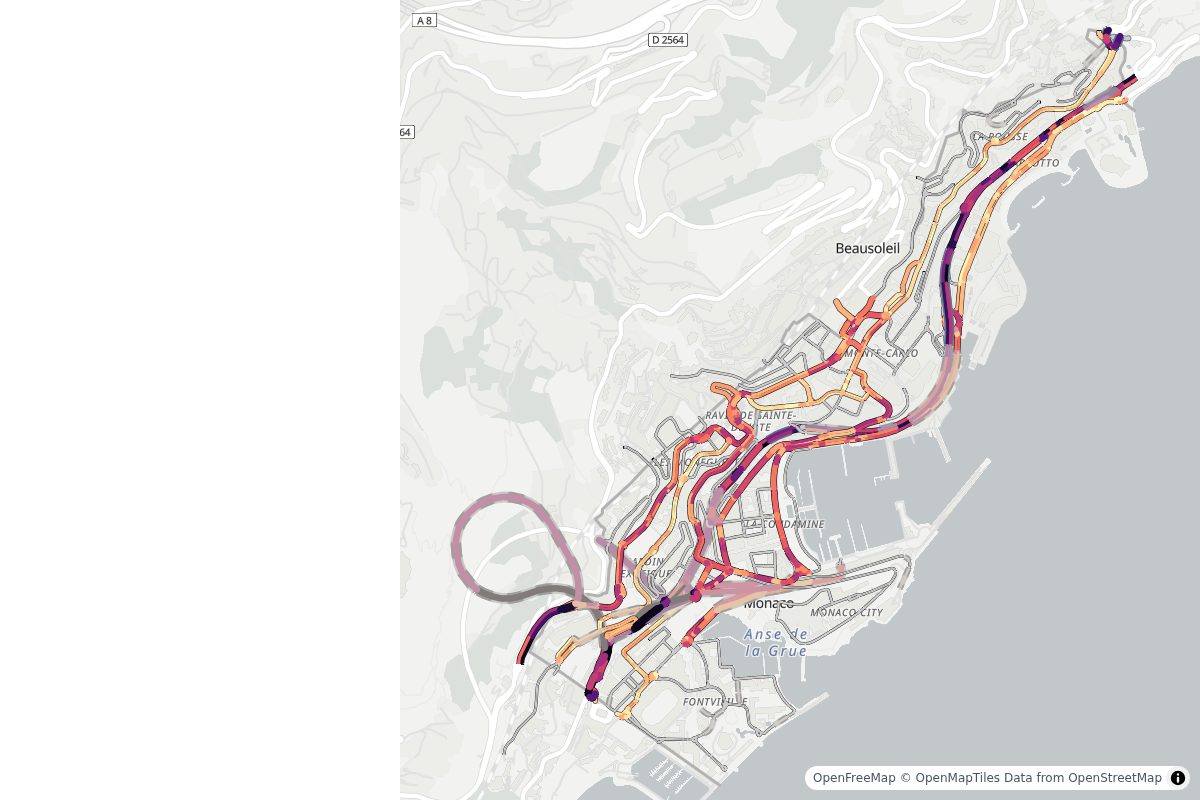

In [13]:
net.driving.dashboard(color_by=by_edge, cmap="magma_r")    # the dashboard, colored by the count; click a road for its card

On this page the output is a picture, so you cannot click it. In your notebook the dashboard is live. The picture
below shows it after a click on Boulevard du Larvotto:

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/dashboard-counts.png" alt="The dashboard of the counts: the colored map, and the card of Boulevard du Larvotto in the panel, with vehicles_per_hour 1151" width="100%">

The table names each part of the picture.

| Part | What it shows |
|---|---|
| the map | each counted road in the color of its count: light for a low count, dark for a high count. The gray roads have no count |
| the card in the panel | the road that you clicked: its name, `edge_id`, `osm_id`, road class, lanes, speed limit and your column `vehicles_per_hour` (1151 for this road) |
| the small box on the map | a short form of the card, at the clicked road |
| the buttons at the right | zoom, 3D, the base map layers and the buildings |

To use it:

1. Run the cell.
2. Click a road on the map.
3. Read its count in the card. Click another road to compare.

| Use | When |
|---|---|
| `net.map(color_by=...)` | you want to see the pattern of the data over the area |
| `net.dashboard(color_by=...)` | you also want to look at single roads and read their values |

To keep the dashboard as a file that opens in any browser, use
`net.save_map("counts.html", dashboard=True, color_by=by_edge, cmap="magma_r")`.

## The same data in more modes

A street with a sidewalk has the same `edge_id` in the driving and in the walking network. So counts that you join to
the driving network are also on the walking network, without a second join key. The walking network is in the same
file, `monaco.duckdb`.

In [14]:
on_walk = counts.edge_id.isin(net.walking.edges().edge_id)                    # the counts that find a walking edge
print(on_walk.sum(), "of", len(counts), "counted edges are also walking edges")

612 of 1013 counted edges are also walking edges


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> 612 of the 1013 counted edges are also in the walking network: the main roads with a sidewalk. The other 401 edges have no walking twin. 55 of them are in tunnels, where walking is not allowed. On others, OSM can draw the sidewalk as a separate way: then the walking network uses that way, not the road.

## The ids stay after a rebuild

Build Monaco again into a new file. The same counts join to the same edges, with no change.

In [15]:
again = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco_again")    # the same area, built again into a new file
counts.edge_id.isin(again.driving.edges().edge_id).all()                              # each count still finds its edge

cut: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco_again-20261121-020037-d786/monaco_again.duckdb

np.True_

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> `True`: each of the 1013 counts finds its edge in the new file. When the OSM data changes (a new extract, or a fix of chapter 5), only the edges of the changed ways get new ids. Chapter 5 shows how to list them with `net.diff`, and chapter 11 shows `duckosm.mobility.edge_id_map`, which connects old ids to new ids.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> To move data from an old build to a new build of other OSM data, join on `edge_id` first. Only the rows that find no edge need more work.

## Try it yourself

**1.** Give each driving edge a made-up speed (for example `maxspeed_kmh` times a random number from 0.6 to 1.0) and draw the map of the speeds.

<details><summary>Show the answer</summary>

```python
edges = net.driving.edges()
rng = np.random.default_rng(2)
speed = edges.set_index("edge_id").maxspeed_kmh * rng.uniform(0.6, 1.0, len(edges))
net.driving.map(color_by=speed.rename("speed_kmh"), cmap="RdYlGn")
```
</details>

**2.** Write the counts to a CSV file, read it again with pandas, and check that the ids are the same.

<details><summary>Show the answer</summary>

```python
counts.to_csv("out/counts.csv", index=False)
import pandas as pd
back = pd.read_csv("out/counts.csv")
back.edge_id.dtype, back.edge_id.equals(counts.edge_id)
```
</details>

**3.** Find the sum of the counts on each named road, with SQL on the Parquet file.

<details><summary>Show the answer</summary>

```python
net.sql("""SELECT e.name, sum(c.vehicles_per_hour) AS vph
           FROM driving.edges e JOIN 'out/counts.parquet' c USING (edge_id)
           WHERE e.name IS NOT NULL GROUP BY e.name ORDER BY vph DESC LIMIT 10""")
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| join | putting two tables together on a key column |
| key | the column that tells which rows belong together: here `edge_id` |
| left join | a join that keeps all rows of the first table. A row without a match gets NULL or `NaN` |
| `int64`, `BIGINT` | a 64-bit integer: the type of `edge_id` in pandas and in DuckDB |
| Parquet | a column file format that keeps the types of the columns |
| `register` | a DuckDB call that gives a DataFrame a table name on a connection |
| vehicles per hour | the number of vehicles that pass one point of a road in one hour |

## Summary

| Call | Does |
|---|---|
| `net.driving.edges(where=...)` | the edges of one mode, filtered in SQL |
| `edges.merge(data, on="edge_id", how="left")` | your data on the edges, in pandas |
| `con.register("name", df)` in `net.connect()` | your DataFrame as a table in SQL |
| `net.sql("... JOIN 'file.parquet' USING (edge_id)")` | your data from a Parquet file, joined in SQL |
| `net.map(color_by=series, cmap=...)` | a map colored by your data |
| `net.map(highlight=ids)` | some edges in orange |
| `net.dashboard(color_by=series, cmap=...)` | the dashboard colored by your data, with the value in the road card |
| `net.save_map(path, color_by=...)` | the map of your data as one HTML file |
| `counts.edge_id.isin(other.edges().edge_id)` | check that your data finds its edges in another file |

The reference: [Python SDK, Maps](../reference/python.md#maps) and [Stable edge ids](../concepts/edge-ids.md). **Next:** [5. Fix the OSM data once](05_osm_fixes.md), a fixes file that every build and every output takes.